In [1]:
# Recurrent Neural Network
# LSTM RNN'in özelleştirilmiş versiyonudur.



## Sequence Models
* Sequence models plays an over time. --Sıralı model zamana bağlı model , Havaalanındaki yolcu sayısını ölçmek istiyorum bu zamanla değişir . Bu sequence modeldir. Konuşuyoruz mesela konuşma zamana göre ses frekansı değişir.
* Speech recognition, natural language process (NLP), music generation
* Apples Siri and Google's voice search
* Sentiment classification (duygu sınıflandırma) Mesela "bu ders bu dunyadaki en guzel ders" yada "sacma sapan ders cekmissin hocaaa"
* ANN ile duygu sınıflandırırsan ders mesela kelimeye bakınca olumlu ya da olumsuz diyemez ancak rnn short memorysi sayesind dersin önündeki dünyadaki en güzel kelimelerini de tutar ve bu sayede olumlu olumsuz yorumu yapılabilir.
* ANN , CNN ile bu  işi yapamayız
* Zamana bağlı bir modelim varsa bunu analiz etmenin , geleceği predict etmenin yollarından biri RNN'dir.

## Recurrent Neural Network
* RNN’s are able to remember important things about the input they received, which enables them to be very precise in predicting what’s coming next.
* This is the reason why they are the preferred algorithm for sequential data like time series, speech, text, financial data, audio, video, weather and much more because they can form a much deeper understanding of a sequence and its context, compared to other algorithms.
* Not only feeds output but also gives feed backs into itself. Because RNN has internal memory (iç hafıza)
* temporal loop = zamansal döngü. Kendini besler.

* ![title](images/22.jpg)

* Hidden layerda nodelar var. Bu nodeların kendi kendin besleyen temporal loopları var. İnternal loop yani geçici hafıza.
* Belleğe sahipler short term memory bir önceki node da olanları hatırlarlar. Eskiyi hatırlar.
* Mesela geçmişi hatırlamak neden önemli biz yaptıklarımızdan bir şeyler öğreniriz ve yeni öğrenilen şeyleri de eski öğrendiklerimizi üzerine kurarız. RNN'i de aynı mantıkta düşünebilirsiniz. Film örneğinde olduğu gibi.
* Basketbolcu basket sahasına giti ne yapacak o anda film biti mesela basket oynayacak, bunu nerden bilebiliriz geçmiş deneyimlerden
* ANN etrafına bakar sadece çünkü memory yok

* ![title](images/23.jpg)

* Hatırlamam gereken şeyleri bir sonraki hidden layer'a aktarıyorum. yani hidden layer hem bu bilgiyi hem de input bilgisine sahip.
* Basketbol örneği , 4 cümle ve predict
* Örnek RNN yapılarına bakalım
* One to Many
    * Input bir resim output o resimde yapılan cümle yani "Adam surf yapıyor"

    * ![title](images/24.jpg)

    * adam----sörf tahtası----dalga---vb.
* Many to One
    * Input bir cümle output bir duygu mesela iyimser neşeli gibi.

    * ![title](images/25.jpg)

* Many to Many
    * Mesela google translate kullanarak İngilizceden bir cümleyi Türkçe'ye translate etmek

    * ![title](images/26.jpg)
    
    * Translate de RNN kullanır.
* RNN short term memory'e sahip ama LSTM long term memory'e de sahip olabiliyor.
* RNN'i ANN yada CNN'den ayıran daha önce de belirttiğimiz gibi *memory*. Mesela "DATAI" diye bir stringimiz var ve biz 4. harfe geldik yani "A" harfine. ANN' e sorduğumuz zaman 4. harfi A olan bir kelimenin 5. harfi ne olabilir diye. ANN bilemez çünkü memory olmadığı için geçmiş harfleri yani "DAT" harflerini bilip "A" ile birleştirip daha sonra 5. harf "I" olabilir diyemez. Ama RNN tam olarak bunu söyleyebilir.
* Exploiding Gradients: Gradient'in çok büyük olması durumu. Gereksiz yere belli weightlere önem kazandırır. Yani gereksiz şeyleri öğrenmiş oluruz.
* Vanishing Gradients: Gradient'in çok küçük olması durumu. Yavaş öğrenir.
* LTSM yukardaki bu iki sorunu da çözecek
* Gradient neydi arkadaşlar costa göre weightlerde ki değişim.
* Özetle RNN de memory var ve bu memory sayesinde zamana bağlı değişkenleri classıfıcatıon  ve predict yapmamız kolaylaşır.
* * Yakın geçmişi hatırlayıp geçmiş ile geleceği bağlayabilirler.Predict edebilirler.

<a id="3"></a>
## Implementing Recurrent Neural Network with Keras
* Keras neural network , deep learning gibi konularda yardımcı olan kütüphane
* Bu kısımda borsada gelecek değeri oluşturmaya çalışacağız.
* keras-gpu yükleyebilirsin.


### Loading and Preprocessing Data

In [6]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')


In [7]:
# Importing the training set
dataset_train = pd.read_csv('Stock_Price_Train.csv') # datam borsa datası

In [8]:
dataset_train.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"


In [9]:
train = dataset_train.loc[:, ["Open"]].values # .values ile arraye çeviriyorum.
train

array([[325.25],
       [331.27],
       [329.83],
       ...,
       [793.7 ],
       [783.33],
       [782.75]])

In [10]:
# Feature Scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range = (0, 1))
train_scaled = scaler.fit_transform(train) # fit ile datamı 0-1 arasına sokarım. Transform edip de datama eşitliyorum.
train_scaled


array([[0.08581368],
       [0.09701243],
       [0.09433366],
       ...,
       [0.95725128],
       [0.93796041],
       [0.93688146]])

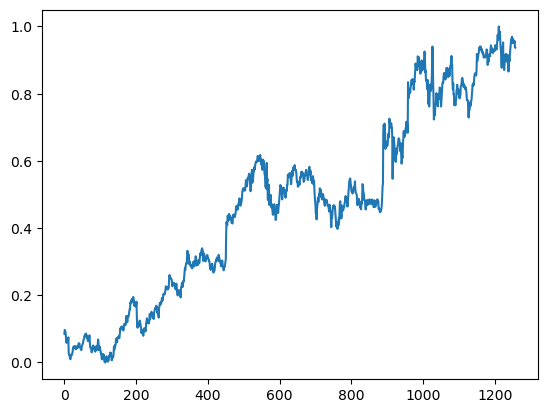

In [11]:
plt.plot(train_scaled)
plt.show()

In [12]:
# Creating a data structure with 50 timesteps and 1 output
X_train = [] # ilk 50 değeri al 50 tane al 51.predict et 50 tane al 51.predict et şeklinde olacak
y_train = [] # 50 tanesine göre 51.sini biliyorum . Buna göre modelimi oluşturucam.
timesteps = 50
for i in range(timesteps, 1258):
    X_train.append(train_scaled[i-timesteps:i, 0])
    y_train.append(train_scaled[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)

![resim](images/27.jpg)

In [14]:
# Reshaping
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_train

array([[[0.08581368],
        [0.09701243],
        [0.09433366],
        ...,
        [0.03675869],
        [0.04486941],
        [0.05065481]],

       [[0.09701243],
        [0.09433366],
        [0.09156187],
        ...,
        [0.04486941],
        [0.05065481],
        [0.05214302]],

       [[0.09433366],
        [0.09156187],
        [0.07984225],
        ...,
        [0.05065481],
        [0.05214302],
        [0.05612397]],

       ...,

       [[0.9313937 ],
        [0.94636878],
        [0.96569685],
        ...,
        [0.95475854],
        [0.95204256],
        [0.95163331]],

       [[0.94636878],
        [0.96569685],
        [0.97510976],
        ...,
        [0.95204256],
        [0.95163331],
        [0.95725128]],

       [[0.96569685],
        [0.97510976],
        [0.95966962],
        ...,
        [0.95163331],
        [0.95725128],
        [0.93796041]]])

In [15]:
X_train.shape

(1208, 50, 1)

In [16]:
y_train

array([0.05214302, 0.05612397, 0.05818885, ..., 0.95725128, 0.93796041,
       0.93688146])

In [17]:
y_train.shape

(1208,)


### Create RNN Model

In [19]:
# Importing the Keras libraries and packages
from keras.models import Sequential # verileri içinde topladığım yapıydı bu.
from keras.layers import Dense # layerları kullandığımız yapı
from keras.layers import SimpleRNN
from keras.layers import Dropout

# Initialising the RNN
regressor = Sequential()

# Adding the first RNN layer and some Dropout regularisation
regressor.add(SimpleRNN(units = 50,activation='tanh', return_sequences = True, input_shape = (X_train.shape[1], 1)))
regressor.add(Dropout(0.2))

# Adding a second RNN layer and some Dropout regularisation
regressor.add(SimpleRNN(units = 50,activation='tanh', return_sequences = True))
regressor.add(Dropout(0.2))

# Adding a third RNN layer and some Dropout regularisation
regressor.add(SimpleRNN(units = 50,activation='tanh', return_sequences = True))
regressor.add(Dropout(0.2))

# Adding a fourth RNN layer and some Dropout regularisation
regressor.add(SimpleRNN(units = 50))
regressor.add(Dropout(0.2))

# Adding the output layer
regressor.add(Dense(units = 1))

# Compiling the RNN
regressor.compile(optimizer = 'adam', loss = 'mean_squared_error')

# Fitting the RNN to the Training set
regressor.fit(X_train, y_train, epochs = 100, batch_size = 32)

# RNN için bu güzel sonuç vermicek . LSTM de güzel sonuç verir.

Epoch 1/100
38/38 [==============================] - 4s 26ms/step - loss: 0.4224
Epoch 2/100
38/38 [==============================] - 1s 27ms/step - loss: 0.2424
Epoch 3/100
38/38 [==============================] - 1s 26ms/step - loss: 0.2016
Epoch 4/100
38/38 [==============================] - 1s 26ms/step - loss: 0.1467
Epoch 5/100
38/38 [==============================] - 1s 26ms/step - loss: 0.1009
Epoch 6/100
38/38 [==============================] - 1s 27ms/step - loss: 0.0816
Epoch 7/100
38/38 [==============================] - 1s 26ms/step - loss: 0.0759
Epoch 8/100
38/38 [==============================] - 1s 26ms/step - loss: 0.0622
Epoch 9/100
38/38 [==============================] - 1s 26ms/step - loss: 0.0505
Epoch 10/100
38/38 [==============================] - 1s 26ms/step - loss: 0.0460
Epoch 11/100
38/38 [==============================] - 1s 26ms/step - loss: 0.0403
Epoch 12/100
38/38 [==============================] - 1s 28ms/step - loss: 0.0329
Epoch 13/100
38/38 [=====


### Predictions and Visualising RNN Model

In [21]:
# Getting the real stock price of 2017
dataset_test = pd.read_csv('Stock_Price_Test.csv')
dataset_test.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2017,778.81,789.63,775.80,786.14,"1,657,300"
1,1/4/2017,788.36,791.34,783.16,786.90,"1,073,000"
2,1/5/2017,786.08,794.48,785.02,794.02,"1,335,200"
3,1/6/2017,795.26,807.90,792.20,806.15,"1,640,200"
4,1/9/2017,806.40,809.97,802.83,806.65,"1,272,400"


In [22]:
real_stock_price = dataset_test.loc[:, ["Open"]].values
real_stock_price

array([[778.81],
       [788.36],
       [786.08],
       [795.26],
       [806.4 ],
       [807.86],
       [805.  ],
       [807.14],
       [807.48],
       [807.08],
       [805.81],
       [805.12],
       [806.91],
       [807.25],
       [822.3 ],
       [829.62],
       [837.81],
       [834.71],
       [814.66],
       [796.86]])

In [23]:
# Getting the predicted stock price of 2017
dataset_total = pd.concat((dataset_train['Open'], dataset_test['Open']), axis = 0)
inputs = dataset_total[len(dataset_total) - len(dataset_test) - timesteps:].values.reshape(-1,1)
inputs = scaler.transform(inputs)  # min max scaler
inputs

array([[0.97510976],
       [0.95966962],
       [0.97808617],
       [1.        ],
       [0.98076494],
       [0.97083116],
       [0.98450406],
       [0.96054394],
       [0.9371419 ],
       [0.92841729],
       [0.90804747],
       [0.8771858 ],
       [0.92153434],
       [0.93809063],
       [0.93165414],
       [0.95254483],
       [0.88812412],
       [0.88637547],
       [0.87032145],
       [0.88563137],
       [0.90743359],
       [0.91571173],
       [0.89941588],
       [0.91805566],
       [0.9089404 ],
       [0.9024853 ],
       [0.89456061],
       [0.91600938],
       [0.9132934 ],
       [0.88979835],
       [0.86589404],
       [0.89030062],
       [0.90335962],
       [0.89642086],
       [0.91777662],
       [0.93176576],
       [0.94114145],
       [0.95762334],
       [0.96413424],
       [0.96402262],
       [0.96971501],
       [0.95077759],
       [0.96294367],
       [0.96123223],
       [0.95475854],
       [0.95204256],
       [0.95163331],
       [0.957

1/1 [==============================] - 1s 610ms/step


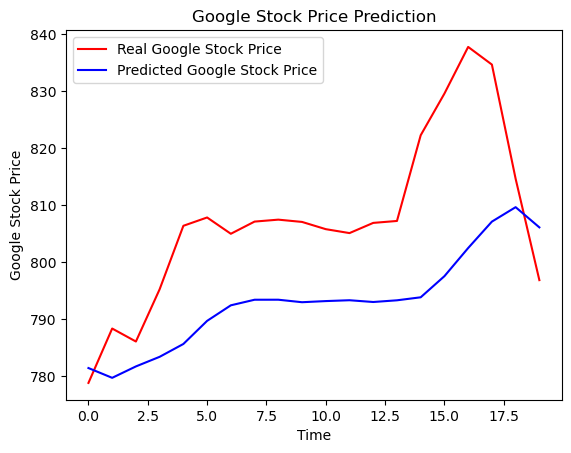

In [24]:
X_test = []
for i in range(timesteps, 70):
    X_test.append(inputs[i-timesteps:i, 0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
predicted_stock_price = regressor.predict(X_test)
predicted_stock_price = scaler.inverse_transform(predicted_stock_price) # predict ettiğim değerler de normalize edilmiş. bunları genişletiyoruz , scale ediyorz.

# Visualising the results
plt.plot(real_stock_price, color = 'red', label = 'Real Google Stock Price')
plt.plot(predicted_stock_price, color = 'blue', label = 'Predicted Google Stock Price')
plt.title('Google Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Google Stock Price')
plt.legend()
plt.show()
# epoch = 250 daha güzel sonuç veriyor.

In [25]:
# kötü bir model oldu


## Long Short Term Memory (LSTMs)
* LSTM is variant of RNN.
* LSTM de RNN'den farklı olarak long term memory var. 
* LSTM architecture:
    * x: scaling of information
    * +: Adding information
    * sigmoid layer. Sigmoid memory den bir şeyi hatırlamak için yada unutmak için kullanılır. 1 yada 0'dır.
    * tanh: activation function tanh. Tanh vanishing gradient(yavaş öğrenme - çok küçük gradient) problemini çözer. Çünkü parametreleri update ederken türev alıyorduk. Tanh'ın türevi hemen sıfır'a ulaşmaz.
    * h(t-1): output of LSTM unit
    * c(t-1): memory from previous LSTM unit
    * X(t): input
    * c(t): new updated memory
    * h(t): output
    * From c(t-1) to c(t) is memory pipeline. or only memory.
    * Oklar vektör.
    * h(t-1) ile X(t) birleşmiyor parallel iki yol olarak düşünebilirsiniz.
* ![Time](images/28.jpg)
* 1) Forget gate: input olarak X(t) ve h(t-1) alır. Gelen bilginin unutulup unutulmayacağına karar verir.
* 2) Input gate: Hangi bilginin memory de depolanıp depolanmayacağına karar verir.
* 3) Output gate: Hangi bilginin output olup olmayacağına karar verir.
* Örneğin: 
    * ... "Boys are watching TV"
    * "On the other hand girls are playing baseball."
    * Forget "boys". new input is "girls" and output is "girls"

* Özelleşmiş bir rnn
* h(t-1) bir önceki değerden  gelen output değerleridir.
* ct-1 : bir önceki unitten gelen memory
* ct : yeni güncellenen memory
* x : memory forget olup olmaması
* .+ : memory update
* sigmoid 1 ise aktarmış olurum,sigmoid 0 ise aktaramam unuturum.Geçmişi unutmuş oluruz.
* tanh - 2 çıkışı 0 sa eklenmez 1 se eklenir.
* üstteki ht LSTM unit outputu
* ht : bu da bir sonrakine aktrabilecel lstm unit outputu

## Implementing Long Short Term Memory with Keras


### Loading and Visualizing Data

In [30]:
import numpy
import pandas as pd 
import matplotlib.pyplot as plt
import math
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error # loss function

In [31]:
data = pd.read_csv('international-airline-passengers.csv',skipfooter=5) #skipfooter ile bu dataları atlıyoruz
data.head(12)

,Month,International airline passengers: monthly totals in thousands. Jan 49 ? Dec 60
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
5,1949-06,135
6,1949-07,148
7,1949-08,148
8,1949-09,136
9,1949-10,119


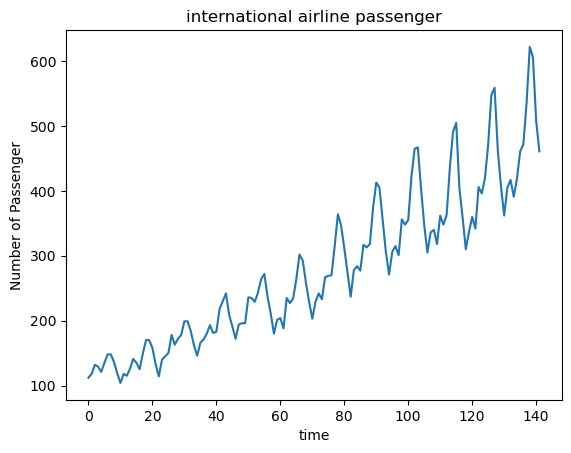

In [32]:
dataset = data.iloc[:,1].values
plt.plot(dataset)
plt.xlabel("time")
plt.ylabel("Number of Passenger")
plt.title("international airline passenger")
plt.show()
# sezona bağlı değişen

In [33]:
# her bir peak yaz ayını ifade eder.
# datamızın belli kısmına kadar eğiticez, train edeceğiz ve predict edeceğiz.


### Preprocessing Data
* reshape
* change type
* scaling
* train test split
* Create dataset

In [35]:
dataset = dataset.reshape(-1,1)
dataset = dataset.astype("float32")
dataset.shape  # 142, --> 142,1

(142, 1)

In [36]:
# neural networklerde scalıng yapmak hızımızı artırır.
# scaling 
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [37]:
train_size = int(len(dataset) * 0.50) # yüzde 50'sini train için alıyorum
test_size = len(dataset) - train_size
train = dataset[0:train_size,:]
test = dataset[train_size:len(dataset),:]
print("train size: {}, test size: {} ".format(len(train), len(test)))

train size: 71, test size: 71 


In [38]:
time_stemp = 10
dataX = []
dataY = []
for i in range(len(train)-time_stemp-1):
    a = train[i:(i+time_stemp), 0]
    dataX.append(a)
    dataY.append(train[i + time_stemp, 0])
trainX = numpy.array(dataX)
trainY = numpy.array(dataY)  # numpy array şeklinde depoluyorum


In [39]:
dataX = []
dataY = []
for i in range(len(test)-time_stemp-1):
    a = test[i:(i+time_stemp), 0]
    dataX.append(a)
    dataY.append(test[i + time_stemp, 0])
testX = numpy.array(dataX)
testY = numpy.array(dataY)  

In [40]:
trainX = numpy.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1])) # neden reshape yapıyoruz, preprecoosing keras modeli ile alakalı uyumlu olsun diye 
testX = numpy.reshape(testX, (testX.shape[0], 1, testX.shape[1]))


### Create LSTM Model

In [42]:
# model
model = Sequential()
model.add(LSTM(10, input_shape=(1, time_stemp))) # 10 lstm neuron(block)
model.add(Dense(1)) # dense 1 de sadece 1 nöron var anlamında . Çıkış katmanı bize sadece bir tane çıktı verecek (tahmini yolcu sayısı)
# dense1 flatten konumda memory gelen tanh şeklinde geliyor. hidden gelen sigmoid geliyor output yolunda buluşuyorlar ve sonuca doğru beraber gidiyor.
model.compile(loss='mean_squared_error', optimizer='adam')
model.fit(trainX, trainY, epochs=50, batch_size=1)

Epoch 1/50
60/60 [==============================] - 2s 1ms/step - loss: 0.0336
Epoch 2/50
60/60 [==============================] - 0s 2ms/step - loss: 0.0078
Epoch 3/50
60/60 [==============================] - 0s 2ms/step - loss: 0.0054
Epoch 4/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0049
Epoch 5/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0044
Epoch 6/50
60/60 [==============================] - 0s 2ms/step - loss: 0.0041
Epoch 7/50
60/60 [==============================] - 0s 2ms/step - loss: 0.0037
Epoch 8/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0035
Epoch 9/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0032
Epoch 10/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0030
Epoch 11/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0029
Epoch 12/50
60/60 [==============================] - 0s 1ms/step - loss: 0.0028
Epoch 13/50
60/60 [==============================


### Predictions and Visualising LSTM Model

In [44]:
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)
# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])
# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

2/2 [==============================] - 0s 2ms/step
Train Score: 18.04 RMSE
Test Score: 38.04 RMSE


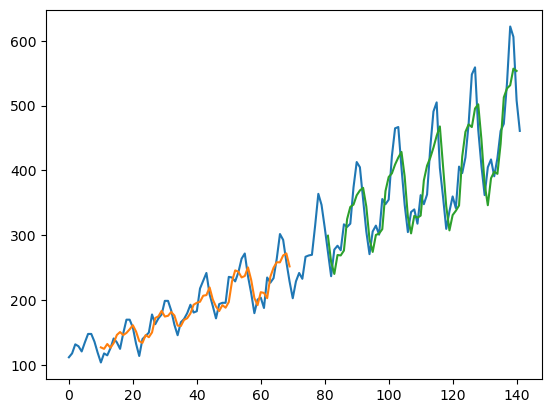

In [45]:
# shifting train
trainPredictPlot = numpy.empty_like(dataset)
trainPredictPlot[:, :] = numpy.nan
trainPredictPlot[time_stemp:len(trainPredict)+time_stemp, :] = trainPredict
# shifting test predictions for plotting
testPredictPlot = numpy.empty_like(dataset)
testPredictPlot[:, :] = numpy.nan
testPredictPlot[len(trainPredict)+(time_stemp*2)+1:len(dataset)-1, :] = testPredict
# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()